# 12 · Tổng hợp: bốn câu hỏi quản trị, KPI và đối chiếu số liệu báo cáo

## 1. Mục tiêu và buổi học áp dụng

Gom kết luận của notebook 07–11 thành câu trả lời cho **cả bốn câu hỏi quản trị**, đặt cạnh bảng KPI AS-IS/TO-BE, và **đối chiếu tự động mọi con số** trong `docs/BAO_CAO_MON_HOC.md` với artifact. Tổng hợp kiến thức Buổi 1–6.

## 2. Đầu vào

Run `outputs/process/<run>` (mọi bước A–E) và báo cáo `docs/BAO_CAO_MON_HOC.md`.

In [1]:
# Mở run giai đoạn 2 đã kiểm fingerprint. Không cần biến môi trường: nếu không chỉ định, tự chọn run
# hoàn tất mới nhất khớp configs/process.yaml hiện tại (bộ chạy `jira-ad notebooks` đặt JIRA_AD_PROCESS_RUN_DIR).
import pandas as pd
from IPython.display import Markdown, display

from jira_ad import process_plots as pp
from jira_ad.process_analysis import fmt, open_process_run

pd.options.display.float_format = "{:.3f}".format
pd.options.display.max_colwidth = 100
run = open_process_run()
print(run.header())

run: outputs/process/20261026T025412Z-399b0a40
chọn run: biến môi trường JIRA_AD_PROCESS_RUN_DIR
config: configs/process.yaml
config_hash: 399b0a40534a3d08466aaaf32175a68cb6d59cf4d90af65301ebb04c5e572a22
code.sha256: ed83115da72a96af6ecac17610d370d96a617635e4abc0c807ee7459ba84e9b6
tạo lúc (UTC): 2026-10-26T02:54:12.298067+00:00
số artifact đã kiểm sha256: 93


In [2]:
import json
display(pd.Series({"bước": ", ".join(sorted({p.split("/")[0] for p in run.manifest["files"]})),
                   "số artifact": len(run.manifest["files"]),
                   "phiên bản": json.dumps({k: v for k, v in run.manifest["versions"].items() if v})},
                  name="run").to_frame())

,run
bước,"a_quant, b_norms, c_conformance, d_bpr, e_ranking"
số artifact,93
phiên bản,"{""python"": ""3.12.7"", ""numpy"": ""2.5.4"", ""pandas"": ""3.0.6"", ""networkx"": ""3.7"", ""scikit-learn"": ""1...."


## 3. Dữ liệu và giả định

Như các notebook 07–11: Jira chỉ có thời điểm đổi trạng thái (PT/WT là xấp xỉ, báo thành khoảng); không có số nhân sự/giờ công (năng lực đo qua thông lượng, phân tích dừng ở vai trò); cập nhật bù được gắn cờ; bot không là nguồn lực; định mức nội suy từ lịch sử; mô hình chuẩn và nhóm nghiệp vụ là giả định của tác giả; mọi số TO-BE là mục tiêu / kịch bản ước tính; "điểm cao" trong xếp hạng = nên xem trước.

## 4. Kết quả

### 4.1 Câu hỏi 1 — Quy trình thực tế chạy thế nào? (Ch1, Ch5)

In [3]:
from jira_ad.process_analysis import (remarks_bpr, remarks_conformance, remarks_norms, remarks_quant,
                                      remarks_ranking)

def show(lines):
    display(Markdown("\n".join(f"- {line}" for line in lines)))

show(remarks_conformance(run))

- Khai phá: inductive có fitness cao nhất (1,000, precision 0,548); heuristics có precision cao nhất (1,000, fitness 0,921) ⇒ không mô hình khai phá nào vừa khớp hết vừa chặt.
- Cờ phổ biến nhất: Đổi trạng thái trong đợt cập nhật bù (69 ca, 42,9%); không cờ nào bằng 0.
- Mô hình chuẩn: 105/161 ca khớp hoàn toàn (65,2%), fitness trung bình theo ca 0,967; fitness token cao vì một token thiếu chỉ trừ ít điểm, nên chỉ số chính là tỉ lệ ca khớp hoàn toàn.
- Vì sao fitness token (0,965) cao hơn tỉ lệ ca khớp: 56 ca không khớp vẫn có fitness trung bình 0,906 (thấp nhất 0,833), vì mỗi ca chỉ sai một vài bước nên chỉ thiếu/thừa vài token trên tổng số token của cả chuỗi.
- Nhánh DONE: 39/83 ca khớp (47,0%).
- Nhánh Rejected: 66/78 ca khớp (84,6%).
- Mô hình phụ fast_track (KHÔNG phải mô hình chuẩn, ứng viên TO-BE): 130 ca khớp (80,7%), giải thích thêm 25 ca.
- Cung To Investigate → Rejected chưa từng xảy ra nhưng được giữ (Quyết định 8): precision 0,915 (bỏ cung: 0,991), fitness không đổi.
- CREATE → To Do: 37 ca, 37 lần; 9 lần nằm trong đợt cập nhật bù; 9 ca chỉ lệch trong đợt bù.
- To Do → Inbox: 11 ca, 11 lần; 10 lần nằm trong đợt cập nhật bù; 10 ca chỉ lệch trong đợt bù.
- Lùi trạng thái: 23 ca, 26 lần; 20 lần nằm trong đợt cập nhật bù; 17 ca chỉ lệch trong đợt bù.
- Mở lại: 8 ca, 9 lần; 8 lần nằm trong đợt cập nhật bù; 7 ca chỉ lệch trong đợt bù.

### 4.2 Câu hỏi 2 — Thời gian đi đâu, vai trò nào là điểm nghẽn? (Ch2, Ch3)

In [4]:
show(remarks_quant(run, run.manifest["config"]["cohorts"][0]))
show(remarks_norms(run))

- 161 ca; CT trung vị 17,0 ngày làm việc (23,0 ngày lịch), P90 74,3 ngày làm việc; theo nhánh: DONE 28,7, Rejected 13,4.
- Tỉ trọng PT (ngày làm việc) dao động 16,7%–59,2% giữa bốn biến thể; phương án chính 16,7%, độ nhạy (To Investigate là làm) 57,0%; khoảng rộng 42,5 điểm % ⇒ kết luận PT/WT phụ thuộc cách xếp To Investigate.
- FPY strict 0,814, adjusted 0,957 (30 ca có lùi/mở lại, 7 ca nếu bỏ lần lùi trong đợt bù).
- 78 ca Rejected tiêu tốn 1.928,6 ngày-issue làm việc; 1 ca bị loại sau khi đã In Progress.
- Little: λ = 0,413 ca/ngày, W = 45,6 ngày, L = 18,8 ca (đồng nhất thức); ca đến nửa đầu/nửa sau kỳ: 109/52.
- Vai trò cổng: PO cho To Investigate (91%); PO cho To Do (75%); PO cho Rejected (88%); SQA cho DONE (54%).

- Ưu tiên 1: To Do với 1.159,3 ngày làm việc vượt định mức (48% tổng), định mức P75 7,8 ngày, vai trò cổng PO.
- Thứ tự ưu tiên: To Do > To Investigate > In Test > INVESTIGATED > __CREATED__ > In Progress > Inbox.
- Theo vai trò chuyển ra: PO gắn với 1.298,1 ngày vượt định mức qua 390 lần chuyển (mức vai trò, không đánh giá cá nhân).
- Phần không gán được vai trò người (bot/unknown/thiếu): 742,9 ngày vượt định mức.
- Trạng thái trung gian nhất trên DFG: In Progress (betweenness 0,367, PageRank 0,245).

### 4.3 Câu hỏi 3 — Bao nhiêu ca lệch, lệch ở đâu? (Ch5, Ch6)

In [5]:
if run.path("c_conformance/deviation_breakdown.csv").is_file():
    display(run.csv("c_conformance/deviation_breakdown.csv").query("branch == 'all'"))
show(remarks_ranking(run))
cons = run.csv("e_ranking/consensus.csv")
display(cons[cons.consensus][["case_id", "share_top", "terminal_status", "n_exceed", "reasons"]])

,category,branch,n_cases,n_occurrences,n_occ_in_burst,n_cases_only_in_burst,n_cases_outside_burst,examples_only_in_burst,examples_outside_burst
0,CREATE → To Do,all,37,37,9,9,28,"bug:TI-4811, bug:TI-4820, bug:TI-4935, bug:TI-5200, bug:TI-5564","bug:TI-4751, bug:TI-4759, bug:TI-4876, bug:TI-4890, bug:TI-4902"
3,To Do → Inbox,all,11,11,10,10,1,"bug:TI-4748, bug:TI-4751, bug:TI-5118, bug:TI-5139, bug:TI-5200",bug:TI-5260
6,Lùi trạng thái,all,23,26,20,17,6,"bug:TI-4617, bug:TI-4748, bug:TI-4751, bug:TI-4811, bug:TI-5118","bug:TI-4686, bug:TI-5153, bug:TI-5260, bug:TI-5269, bug:TI-5480"
9,Mở lại,all,8,9,8,7,1,"bug:TI-4584, bug:TI-4671, bug:TI-4723, bug:TI-4871, bug:TI-5362",bug:TI-4872


- Biểu diễn: đã dùng embedding của outputs/runs/20261017T081309Z-930f8a85 (đã kiểm fingerprint, không fit lại).
- Tìm lại nhóm nghiệp vụ của activity (1-NN): Node2Vec 0,449, bậc + trung tâm 0,286, baseline lớp phổ biến 0,245 ⇒ Node2Vec tốt hơn đặc trưng cấu trúc.
- K-means: NMI cao nhất 0,388 (node2vec_v1, K = 6); silhouette của Node2Vec tối đa 0,137 ⇒ cấu trúc cụm yếu.
- Chiều M_markov: điểm out-of-fold M_markov từ outputs/improvement/20261022T151529Z-bb0fee9a (sha256 98b34f56ff56e6ee…).
- Top 17 ca (nên xem trước, không phải vi phạm): tỉ lệ Rejected 52,9% so với 48,4% toàn bộ; Spearman điểm–độ dài -0,005.
- Khử độ dài: Spearman M_markov–độ dài từ 0,507 xuống 0,040.
- Ổn định top-17 qua bootstrap: Jaccard trung bình 0,40 [0,21; 0,62] ⇒ danh sách chỉ ổn định vừa phải.
- Danh sách đồng thuận (nằm trong top ở >= 70% số lần bootstrap): 10 ca đồng thuận: bug:TI-4584, bug:TI-4671, bug:TI-4748, bug:TI-5260, bug:TI-5564, bug:TI-4872, bug:TI-5770, bug:TI-6208, bug:TI-5261, bug:TI-6163.
- Riêng số chiều vượt có Spearman 0,121 với độ dài; điểm tổng gần như không tương quan vì phân vị trung bình được tính trong nhóm cùng độ dài.

,case_id,share_top,terminal_status,n_exceed,reasons
0,bug:TI-4584,1.000,DONE,5,"lệch mô hình chuẩn (1 − fitness) = 0,125 (phân vị 98 trong nhóm DONE·dài); số cờ quy tắc = 3 (ph..."
1,bug:TI-4671,1.000,Rejected,5,"lệch mô hình chuẩn (1 − fitness) = 0,125 (phân vị 95 trong nhóm Rejected·ngắn); số cờ quy tắc = ..."
2,bug:TI-4748,1.000,DONE,3,lùi trạng thái/mở lại = 2 (phân vị 97 trong nhóm DONE·dài); đổi người phụ trách = 7 (phân vị 100...
3,bug:TI-5260,1.000,Rejected,5,"lệch mô hình chuẩn (1 − fitness) = 0,125 (phân vị 100 trong nhóm Rejected·vừa); số cờ quy tắc = ..."
4,bug:TI-5564,1.000,DONE,3,số cờ quy tắc = 4 (phân vị 100 trong nhóm DONE·dài); lùi trạng thái/mở lại = 2 (phân vị 97 trong...
5,bug:TI-4872,0.978,Rejected,4,"lệch mô hình chuẩn (1 − fitness) = 0,125 (phân vị 95 trong nhóm Rejected·ngắn); số cờ quy tắc = ..."
6,bug:TI-5770,0.931,DONE,3,"lệch mô hình chuẩn (1 − fitness) = 0,125 (phân vị 94 trong nhóm DONE·vừa); số cờ quy tắc = 2 (ph..."
7,bug:TI-6208,0.881,DONE,3,"lệch mô hình chuẩn (1 − fitness) = 0,154 (phân vị 100 trong nhóm DONE·vừa); lùi trạng thái/mở lạ..."
8,bug:TI-5261,0.880,Rejected,2,"lệch mô hình chuẩn (1 − fitness) = 0,167 (phân vị 99 trong nhóm Rejected·ngắn); độ bất ngờ M_mar..."
9,bug:TI-6163,0.876,DONE,2,lùi trạng thái/mở lại = 2 (phân vị 100 trong nhóm DONE·vừa); độ bất ngờ M_markov (khử độ dài) = ...


### 4.4 Câu hỏi 4 — Tái thiết kế và KPI (Ch4)

- early_triage: ủng hộ — 78 ca Rejected; trung vị 13,4 ngày làm việc tới khi bị loại; 47/78 ca bị loại ngay sau INVESTIGATED (phép kiểm đo quy mô vấn đề, không đo được bao nhiêu ca có thể quyết sớm hơn).
- auto_transition: ủng hộ — 39/58 ca; trễ trung vị 1,7 ngày lịch giữa liên kết đầu tiên và lúc chuyển In Progress; liên kết đầu rơi vào: To Investigate 22, To Do 12, __CREATED__ 5 (cung tự động To Do → In Progress chỉ áp dụng cho 12 ca).
- merge_investigated: ủng hộ — 43/62 lần chuyển; trung vị 0,0 ngày.
- reduce_po_dependency: không ủng hộ — 46 lượt PO (trung vị 0,0 ngày) so với 25 lượt vai trò khác (trung vị 0,0 ngày); CI 95% [0,0; 0,9].
- early_duplicate_detection: không ủng hộ — 7 ca Rejected có liên kết 'link to duplicates'; trung vị 3,2 ngày làm việc tới khi bị loại.
- add_investigating_state: ủng hộ — PT chính 16,7%, nếu To Investigate là làm 57,0%.
- fast_track: ủng hộ — 32 ca bỏ điều tra: CT 11,2 ngày, FPY 0,75; 51 ca có điều tra: CT 35,9 ngày, FPY 0,76.
- ct_work_median_days: AS-IS (đo) 17,0 → TO-BE 15,2 (mục tiêu / kịch bản ước tính; kịch bản từ chối khi kết thúc điều tra + giới hạn chờ To Do).
- ct_work_p90_days: AS-IS (đo) 74,3 → TO-BE 57,9 (mục tiêu / kịch bản ước tính; kịch bản từ chối khi kết thúc điều tra + giới hạn chờ To Do).
- ct_work_median_days_upper: AS-IS (đo) 17,0 → TO-BE 5,9 (mục tiêu / kịch bản ước tính; kịch bản early_triage cận trên + giới hạn chờ To Do).
- rejected_issue_days_work: AS-IS (đo) 1.928,6 → TO-BE 1.394,2 (mục tiêu / kịch bản ước tính; kịch bản từ chối khi kết thúc điều tra).
- rejected_issue_days_work_upper: AS-IS (đo) 1.928,6 → TO-BE 264,2 (mục tiêu / kịch bản ước tính; kịch bản early_triage cận trên).
- pt_share_main: AS-IS (đo) 16,7% → TO-BE 16,9% (mục tiêu / kịch bản ước tính; kịch bản auto_transition).
- status_changes_per_case: AS-IS (đo) 4,4 → TO-BE 5,4 (mục tiêu / kịch bản ước tính; kịch bản đường TO-BE).
- conformance_share_fit: AS-IS (đo) 65,2% → TO-BE 80,7% (mục tiêu / kịch bản ước tính; kịch bản fast_track).
- Mô tả bổ sung (không phải phán quyết): 60,5% số ngày vượt định mức ở To Do rơi vào lượt do PO chuyển ra dù phép kiểm theo trung vị không ủng hộ ⇒ dồn đọng nằm ở đuôi phân bố.

,kpi,unit,asis,tobe,tobe_label,scenario
0,ct_work_median_days,ngày làm việc,17.032,15.212,mục tiêu / kịch bản ước tính,từ chối khi kết thúc điều tra + giới hạn chờ To Do
1,ct_work_p90_days,ngày làm việc,74.307,57.876,mục tiêu / kịch bản ước tính,từ chối khi kết thúc điều tra + giới hạn chờ To Do
2,ct_work_median_days_upper,ngày làm việc,17.032,5.873,mục tiêu / kịch bản ước tính,early_triage cận trên + giới hạn chờ To Do
3,rejected_issue_days_work,ngày-issue làm việc,1928.560,1394.208,mục tiêu / kịch bản ước tính,từ chối khi kết thúc điều tra
4,rejected_issue_days_work_upper,ngày-issue làm việc,1928.560,264.233,mục tiêu / kịch bản ước tính,early_triage cận trên
5,pt_share_main,tỉ lệ,0.167,0.169,mục tiêu / kịch bản ước tính,auto_transition
6,status_changes_per_case,lần/ca,4.435,5.429,mục tiêu / kịch bản ước tính,đường TO-BE
7,conformance_share_fit,tỉ lệ ca khớp,0.652,0.807,mục tiêu / kịch bản ước tính,fast_track


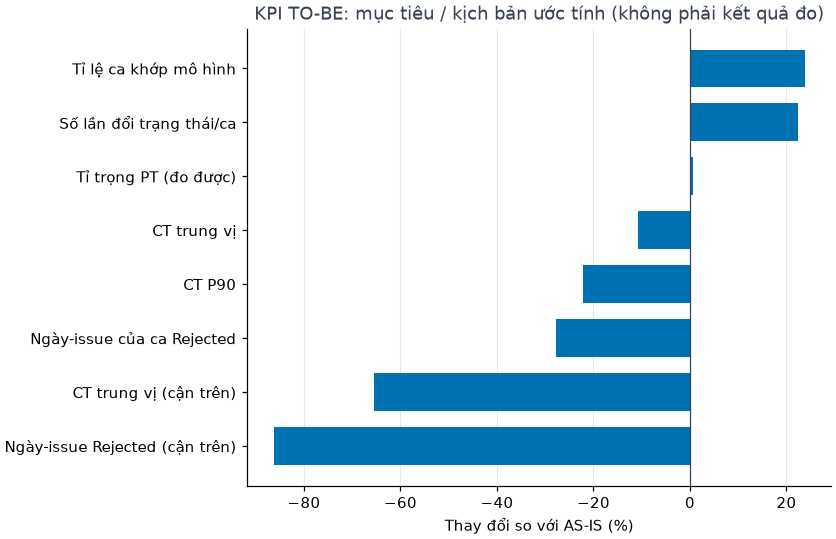

In [6]:
show(remarks_bpr(run))
kpi = run.csv("d_bpr/kpi_asis_tobe.csv")
display(kpi[["kpi", "unit", "asis", "tobe", "tobe_label", "scenario"]])
_ = run.show(pp.plot_kpi_delta(kpi))

### 4.5 Đối chiếu tự động mọi con số trong báo cáo

In [7]:
from jira_ad.process_report import artifact_values, check_report, extract_numbers

report = run.project_root / "docs" / "BAO_CAO_MON_HOC.md"
if report.is_file():
    text = report.read_text(encoding="utf-8")
    missing = check_report(text, artifact_values(run.run_dir))
    display(Markdown(f"Đã đối chiếu **{len(extract_numbers(text))}** con số; chưa khớp: **{len(missing)}**."))
    if missing:
        display(pd.DataFrame([{"số": m.token, "ngữ cảnh": m.context} for m in missing]))
else:
    display(Markdown(f"Chưa có báo cáo ở `{report.relative_to(run.project_root)}`."))

Đã đối chiếu **401** con số; chưa khớp: **0**.

## 5. Quá trình nghiên cứu

- **Quyết định của người dùng làm đổi phương án**: phân loại làm/chờ (Quyết định 2), thay ba quy tắc kiểm định bằng mô hình chuẩn + 7 cờ (Quyết định 4), duyệt mô hình chuẩn và thêm mô hình "luồng nhanh" (Quyết định 8), notebook bắt buộc cho mọi bước (Quyết định 9), cắt Graph2Vec (Quyết định 5).
- **Lỗi thật đã sửa** (có test hồi quy): DFG hoạt động bị tính không trọng số (Ruling 80); hình Petri net không tái lập do tên nút của pm4py (Ruling 85); kết luận viết cứng sai cho story (Ruling 91); lỗi f-string tự gây làm lần chạy thật thất bại (Ruling 97).
- **Kết quả âm được giữ**: giả thuyết phụ thuộc PO và phát hiện trùng sớm không được ủng hộ; độ ổn định của danh sách top chỉ vừa phải; lợi ích đo lường của tự chuyển trạng thái nhỏ.
- **Kiểm chéo**: mỗi bước có ít nhất một con số tính lại bằng pandas thô không import `jira_ad`; mọi số trong báo cáo được đối chiếu ở mục 4.5.

## 6. Nhận xét sinh từ số liệu

In [8]:
kpi_rows = run.csv("d_bpr/kpi_asis_tobe.csv").set_index("kpi")
summary = run.json("c_conformance/replay_summary.json")["by_branch"]["all"] \
    if run.path("c_conformance/replay_summary.json").is_file() else None
lines = [f"CT trung vị AS-IS {fmt(kpi_rows.loc['ct_work_median_days', 'asis'], 1)} ngày làm việc; "
         f"kịch bản TO-BE {fmt(kpi_rows.loc['ct_work_median_days', 'tobe'], 1)} (mục tiêu / kịch bản ước tính)."]
if summary:
    lines.append(f"{summary['n_fit']}/{summary['n_cases']} ca khớp hoàn toàn mô hình chuẩn "
                 f"({fmt(summary['share_fit'], 1, percent=True)}).")
checks = run.csv("d_bpr/checks.csv")
lines.append(f"{int((checks.verdict == 'ủng hộ').sum())}/{len(checks)} ứng viên BPR được dữ liệu ủng hộ.")
show(lines)

- CT trung vị AS-IS 17,0 ngày làm việc; kịch bản TO-BE 15,2 (mục tiêu / kịch bản ước tính).
- 105/161 ca khớp hoàn toàn mô hình chuẩn (65,2%).
- 5/7 ứng viên BPR được dữ liệu ủng hộ.

## 7. Giả định, giới hạn, việc tiếp theo

- Một team, 161 bug đã đóng, không có nhãn lỗi thật; mô hình chuẩn và nhóm nghiệp vụ là giả định; PT/WT xấp xỉ.
- Việc tiếp theo theo giá trị: (1) người hiểu quy trình rà soát bảng mù của notebook 11; (2) pilot TO-BE theo kế hoạch ở notebook 10, đo lại bằng cùng lệnh; (3) thêm trạng thái Investigating để đo được công sức điều tra.